In [1]:
import os, subprocess, shutil
from os import path
from pathlib import Path
import numpy as np
import torch
from tqdm.notebook import tqdm
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import squareform
import matplotlib.pyplot as plt
import json

import itertools
from scipy.cluster.hierarchy import linkage, fcluster
from utils import *

print(f"✅ PyTorch: {torch.__version__}, CUDA: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

✅ PyTorch: 2.10.0+cu128, CUDA: True
GPU: NVIDIA GeForce RTX 5090


In [ ]:
# # Event Segmentation Pipeline for Toy Car Disassembly and Assembly
# 
# ## 🎯 Task Objectives
# - **Atomic Events**: Removing/installing a single screw, removing/installing a single component (3–8 seconds)
# - **Mid-level events**: Removing/installing the left wheel, right wheel, body, etc. (15–30 seconds)
# - **Top-level events**: Disassembling the toy car vs. assembling the toy car (1–2.5 minutes)

# ## 🔧 Environment Setup

# ## 📹 Configuration Parameters

# ========== Basic Configuration ==========
VIDEO_PATH = "NExTVideo"
OUTPUT_DIR = "pipeline_output"
PREPROCESSED_DIR = "preprocessed_frames"
FEATURES_DIR = "features"
FPS = 10
BATCH_SIZE = 256
CLEAN_FRAMES = False
REUSE_EXISTING_FRAMES = True

# ========== Segmentation Strategy ==========
# Complete Enhanced Segmentation Process:
# 1. Asymmetric sliding window (adaptive parameter search)
#    - Window Size: 10/12/15 frames
#    - Threshold: 0.72/0.74/0.76/0.80
#    - Similarity Method: Cosine
# 2. Traditional Differential Peak Detection (85th percentile, Savitzky-Golay filtering)
# 3. Merge two candidate tracks (deduplicate with a minimum interval of 0.3s)
# 4. Refine boundaries (select the point with the maximum gradient within ±0.3s)
# 5. Quality fallback (select the best single method when score < 0.5)

# ========== Hierarchical Configuration ==========
HIERARCHY_CONFIG = {
    'sigma': 30.0,  # Time-scale bandwidth (seconds) – Reduce to enhance locality
    'cut_levels': {
        'atomic': None,           # Atomic level (no segmentation)
        'component': 70,          # Component level (e.g., single wheel)
        'side': 85,               # Side level (e.g., left/right)
        'activity': 95            # Activity level (disassembly/assembly)
    }
}

device = "cuda" if torch.cuda.is_available() else "cpu"

In [21]:
video_name = "2399811629"
segmentation_output_dir = Path("outputs")
segmentation_output_dir.mkdir(parents=True, exist_ok=True)
features = torch.load(Path(FEATURES_DIR) / (VIDEO_PATH + f"_{FPS}FPS") / f"{video_name}.pt")
features = features.cpu().numpy()

✅ Segmentation algorithm loaded (Enhanced version: Asymmetric Window + Differential Peak + Fusion + Refinement)

[Step 3/3] Atomic-level Event Segmentation

----------------------------------------------------------------------
🔹 Step 1: Asymmetric Sliding Window Segmentation...

🔍 Adaptive search space:
   Window sizes: [10, 12, 15] frames = [1.0, 1.2, 1.5] seconds
   Similarity thresholds: [0.72, 0.74, 0.76, 0.8]
   Similarity methods: ['cosine']
   ✓ Found 9 boundaries
   ✓ Best parameters: ws=15, thr=0.72
   ✓ Quality score: 0.300

🔹 Step 2: Differential Peak Detection...
   ✓ Found 10 boundaries

🔹 Step 3: Fusion and Refinement...
   ✓ After fusion: 9 boundaries

📊 Final Statistics:
   Number of Boundaries: 9
   Number of Segments: 10
   Average Segment Length: 1.6 seconds
   Final Quality Score: 0.060
   使用方法: asymmetric_only
----------------------------------------------------------------------

✅ Atomic segmentation completed
✅ Atomic segmentation JSON: outputs/2399811629_atomi

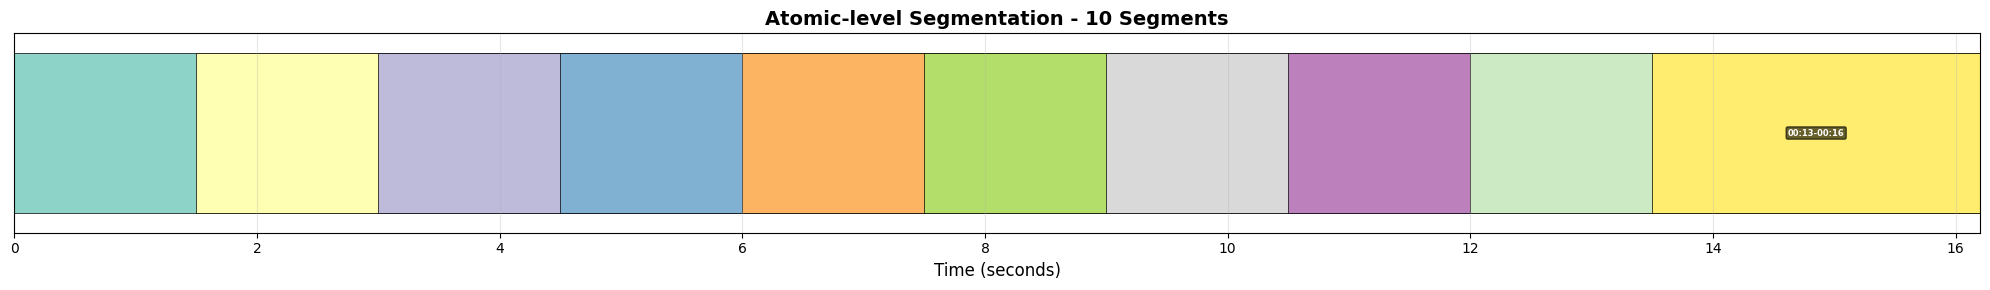

✅ Atomic segmentation visualization: outputs/2399811629_atomic_segments.png


In [22]:
print("✅ Segmentation algorithm loaded (Enhanced version: Asymmetric Window + Differential Peak + Fusion + Refinement)")

# ## Step 3: Execute Atomic Segmentation


print("\n" + "="*70)
print("[Step 3/3] Atomic-level Event Segmentation")
print("="*70)

# Perform a complete enhanced segmentation (asymmetric windowing + differential peak detection + fusion + refinement)）
boundaries, params = enhanced_runner(features, FPS)

results = {'asymmetric': {'boundaries': boundaries, 'params': params}}

print("\n✅ Atomic segmentation completed")

# ## Save the atomic segmentation results

T = features.shape[0]
segs = create_segments(boundaries, T)

json_data = {
    'video_name': video_name,
    'num_frames': int(T),
    'fps': float(FPS),
    'video_duration': round(T / FPS, 3),
    'num_boundaries': len(boundaries),
    'num_segments': len(segs),
    'boundaries_frame_indices': [int(b) for b in boundaries],
    'boundaries_timestamps': [round(b / FPS, 3) for b in boundaries],
    'segments_timestamps': [[round(s[0]/FPS, 3), round(s[1]/FPS, 3)] for s in segs],
    'method': 'enhanced_asymmetric_hybrid',
    'parameters': params
}

out_path = segmentation_output_dir / f"{video_name}_atomic_segmentation.json"
with open(out_path, 'w', encoding='utf-8') as f:
    json.dump(json_data, f, ensure_ascii=False, indent=2)

print(f"✅ Atomic segmentation JSON: {out_path}")

# Visualize atomic segmentation
fig, ax = plt.subplots(figsize=(20, 3))
colors = plt.cm.Set3(np.linspace(0, 1, len(segs)))

for idx, (start, end) in enumerate(segs):
    ax.barh(0, end-start, left=start/FPS, height=0.8, 
            color=colors[idx % len(colors)], edgecolor='black', linewidth=0.5)
    # Add a timestamp (mm:ss-mm:ss)
    seg_center = (start + end) / 2 / FPS
    start_time = start / FPS
    end_time = end / FPS
    
    start_min = int(start_time // 60)
    start_sec = int(start_time % 60)
    end_min = int(end_time // 60)
    end_sec = int(end_time % 60)
    
    time_label = f'{start_min:02d}:{start_sec:02d}-{end_min:02d}:{end_sec:02d}'
    
    if (end - start) / FPS > 2:  # Only display time on longer segments
        ax.text(seg_center, 0, time_label, ha='center', va='center', 
                fontsize=6, color='white', fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.2', facecolor='black', alpha=0.6))

ax.set_xlim(0, T/FPS)
ax.set_ylim(-0.5, 0.5)
ax.set_yticks([])
ax.set_xlabel('Time (seconds)', fontsize=12)
ax.set_title(f'Atomic-level Segmentation - {len(segs)} Segments', fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3, axis='x')

plt.tight_layout()
atomic_viz_path = segmentation_output_dir / f"{video_name}_atomic_segments.png"
plt.savefig(atomic_viz_path, dpi=150, bbox_inches='tight')
plt.show()

print(f"✅ Atomic segmentation visualization: {atomic_viz_path}")


Phase I: 构建语义一致性图谱 (SCM)
Number of atomic units: 10
Atomic feature matrix: (10, 512)
Time center range: 0.75s ~ 14.85s

✅ SCM building completed
   Matrix size: (10, 10)
   Time-resolved bandwidth σ: 30.0秒
   Affinity range: [0.8887, 1.0010]


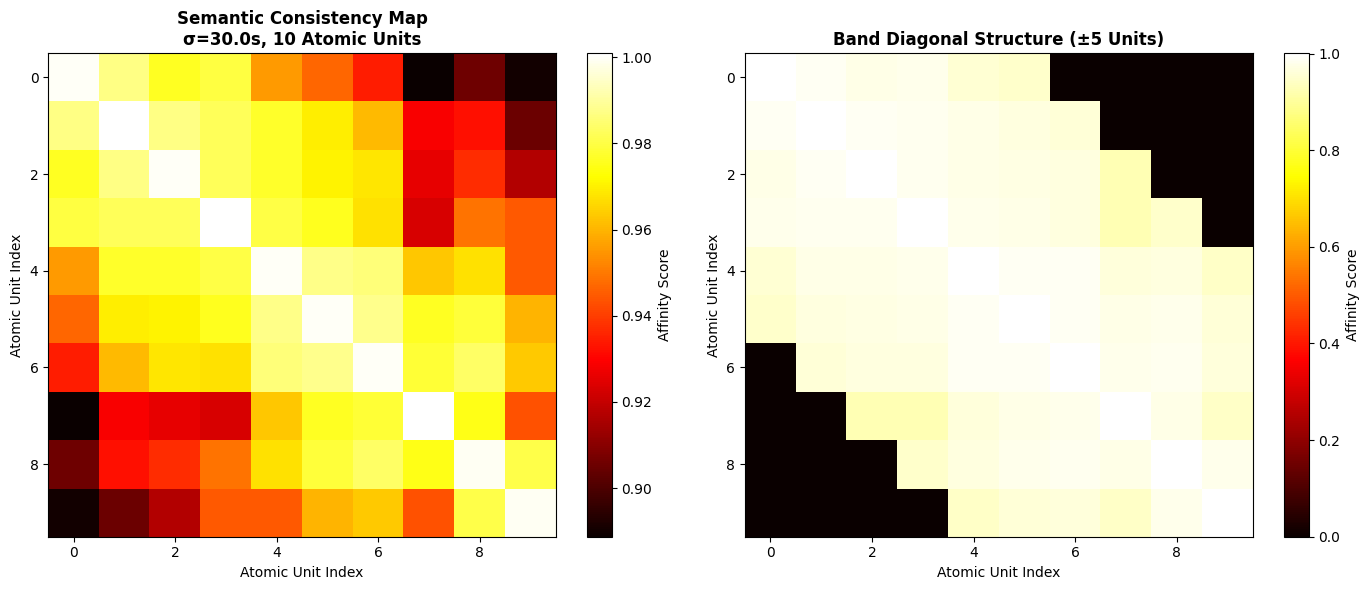

✅ SCM visualization: outputs/2399811629_SCM.png


In [ ]:
# ## Phase I: Building a Semantic Consistency Map


print("\n" + "="*70)
print("Phase I: Building a Semantic Consistency Map (SCM)")
print("="*70)

K = len(boundaries) + 1  # Number of atomic units
print(f"Number of atomic units: {K}")





# Extract atomic unit features
atomic_features, atomic_centers = extract_atomic_features(features, boundaries, FPS)

print(f"Atomic feature matrix: {atomic_features.shape}")
print(f"Time center range: {atomic_centers[0]:.2f}s ~ {atomic_centers[-1]:.2f}s")





# Building an SCM
sigma = HIERARCHY_CONFIG['sigma']
SCM = build_semantic_consistency_map(atomic_features, atomic_centers, sigma)

print(f"\n✅ SCM building completed")
print(f"   Matrix size: {SCM.shape}")
print(f"   Time-resolved bandwidth σ: {sigma}秒")
print(f"   Affinity range: [{SCM.min():.4f}, {SCM.max():.4f}]")


# Visualize SCM
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

im1 = axes[0].imshow(SCM, cmap='hot', aspect='auto', interpolation='nearest')
axes[0].set_title(
    f'Semantic Consistency Map\nσ={sigma}s, {K} Atomic Units',
    fontsize=12, fontweight='bold'
)
axes[0].set_xlabel('Atomic Unit Index', fontsize=10)
axes[0].set_ylabel('Atomic Unit Index', fontsize=10)
plt.colorbar(im1, ax=axes[0], label='Affinity Score')

band_width = min(15, K//2)
band_mask = np.abs(np.arange(K)[:, None] - np.arange(K)[None, :]) <= band_width
SCM_band = SCM.copy()
SCM_band[~band_mask] = 0

im2 = axes[1].imshow(SCM_band, cmap='hot', aspect='auto', interpolation='nearest')
axes[1].set_title(
    f'Band Diagonal Structure (±{band_width} Units)',
    fontsize=12, fontweight='bold'
)
axes[1].set_xlabel('Atomic Unit Index', fontsize=10)
axes[1].set_ylabel('Atomic Unit Index', fontsize=10)
plt.colorbar(im2, ax=axes[1], label='Affinity Score')

plt.tight_layout()
scm_path = segmentation_output_dir / f"{video_name}_SCM.png"
plt.savefig(scm_path, dpi=150, bbox_inches='tight')
plt.show()

print(f"✅ SCM visualization: {scm_path}")

In [ ]:

# ## Phase II: Analysis of Hierarchical Topology (Ward's HAC)


print("\n" + "="*70)
print("Phase II: Analysis of Hierarchical Topology (Ward's HAC)")
print("="*70)





distance_matrix = similarity_to_distance(SCM)
condensed_distance = squareform(distance_matrix, checks=False)

# Ward's Hierarchical Clustering
linkage_matrix = linkage(condensed_distance, method='ward')
merge_distances = linkage_matrix[:, 2]

print(f"✅ Hierarchical clustering completed")
print(f"   Merge distance range: [{merge_distances.min():.4f}, {merge_distances.max():.4f}]")


# Visualize the dendrogram
fig, ax = plt.subplots(figsize=(18, 8))
dendrogram_data = dendrogram(
    linkage_matrix,
    ax=ax,
    color_threshold=np.percentile(merge_distances, 85),
    above_threshold_color='gray',
    leaf_font_size=6
)
ax.set_title(
    f'Hierarchical Dendrogram - {video_name} ({K} Atomic Units)',
    fontsize=14, fontweight='bold'
)
ax.set_xlabel('Atomic Unit Index', fontsize=12)
ax.set_ylabel('Ward Distance', fontsize=12)
ax.grid(True, alpha=0.3, axis='y')

# Add a divider
cut_levels = HIERARCHY_CONFIG['cut_levels']
for level_name, percentile in cut_levels.items():
    if percentile is not None:
        threshold = np.percentile(merge_distances, percentile)
        ax.axhline(y=threshold, color='red', linestyle='--', linewidth=1.5, alpha=0.7)
        ax.text(K*0.98, threshold, f'{level_name} ({percentile}%)', 
                verticalalignment='bottom', fontsize=9, color='red')

plt.tight_layout()
dendrogram_path = output_dir / f"{video_name}_dendrogram.png"
plt.savefig(dendrogram_path, dpi=150, bbox_inches='tight')
plt.show()

print(f"✅ Dendrogram: {dendrogram_path}")

# ## Multi-Granularity Segmentation

# %%
print("\n" + "="*70)
print("Multi-Granularity Event Segmentation")
print("="*70)

hierarchical_segmentations = {}
cut_levels = HIERARCHY_CONFIG['cut_levels']

for level_name, percentile in cut_levels.items():
    if percentile is None:
        # No cutting at the atomic level
        hierarchical_segmentations[level_name] = {
            'threshold': 0.0,
            'num_events': K,
            'labels': np.arange(1, K+1)
        }
        print(f"{level_name:12s}: {K:3d} an atomic unit")
    else:
        threshold = np.percentile(merge_distances, percentile)
        cluster_labels = fcluster(linkage_matrix, threshold, criterion='distance')
        num_clusters = len(np.unique(cluster_labels))
        
        hierarchical_segmentations[level_name] = {
            'threshold': threshold,
            'num_events': num_clusters,
            'labels': cluster_labels
        }
        
        print(f"{level_name:12s}: {num_clusters:3d} events "
              f"(average {K/num_clusters:.1f} atoms/event, threshold={threshold:.3f})")

# %%
# Visualize multi-granularity segmentation
fig, axes = plt.subplots(len(hierarchical_segmentations), 1, 
                         figsize=(20, 2*len(hierarchical_segmentations)))

level_names = ['atomic', 'component', 'side', 'activity']

for idx, (level_name, ax) in enumerate(zip(level_names, axes)):
    level_data = hierarchical_segmentations[level_name]
    labels = level_data['labels']
    num_events = level_data['num_events']
    colors = plt.cm.tab20(np.linspace(0, 1, num_events))
    
    # Visualize each atomic unit
    for i in range(K):
        cluster_id = labels[i] - 1
        color = colors[cluster_id % len(colors)]
        ax.barh(0, 1, left=i, height=0.8, color=color, edgecolor='white', linewidth=0.5)
    
    # Add event boundaries and time annotations (mm:ss-mm:ss)
    event_boundaries = []
    for i in range(1, K):
        if labels[i] != labels[i-1]:
            event_boundaries.append(i)
    
    # Mark the start and end times for each event
    prev_boundary = 0
    for boundary in event_boundaries + [K]:
        event_center_idx = (prev_boundary + boundary) / 2
        
        # Calculate the start and end times of the event (in seconds)
        start_idx = int(prev_boundary) if prev_boundary < len(atomic_centers) else len(atomic_centers) - 1
        end_idx = int(boundary - 1) if boundary - 1 < len(atomic_centers) else len(atomic_centers) - 1
        
        start_time = atomic_centers[start_idx]
        end_time = atomic_centers[end_idx]
        
        # Format as mm:ss
        start_min = int(start_time // 60)
        start_sec = int(start_time % 60)
        end_min = int(end_time // 60)
        end_sec = int(end_time % 60)
        
        time_label = f'{start_min:02d}:{start_sec:02d}-{end_min:02d}:{end_sec:02d}'
        
        # Only display time on larger events
        if (boundary - prev_boundary) > K * 0.03:  # Events account for more than 3%
            ax.text(event_center_idx, 0, time_label, ha='center', va='center',
                    fontsize=7, color='white', fontweight='bold',
                    bbox=dict(boxstyle='round,pad=0.3', facecolor='black', alpha=0.7))
        
        # Visualize segment boundaries
        if boundary < K:
            ax.axvline(x=boundary, color='black', linestyle='-', linewidth=2, alpha=0.8)
        
        prev_boundary = boundary
    
    ax.set_xlim(0, K)
    ax.set_ylim(-0.5, 0.5)
    ax.set_yticks([])
    ax.set_xlabel('Atomic Unit Index', fontsize=10)
    ax.set_title(
        f'{level_name.upper()} Level - {num_events} Events',
        fontsize=11, fontweight='bold'
    )
    ax.grid(True, alpha=0.3, axis='x')

plt.tight_layout()
hierarchy_path = output_dir / f"{video_name}_hierarchy.png"
plt.savefig(hierarchy_path, dpi=150, bbox_inches='tight')
plt.show()

print(f"\n✅ Hierarchical Segmentation Visualization: {hierarchy_path}")


# ## Save the hierarchy results

# %%
# Save the hierarchy as JSON
hierarchy_json = {
    'video_name': video_name,
    'num_atomic_units': int(K),
    'scm_sigma': float(sigma),
    'linkage_method': 'ward',
    'hierarchical_levels': {}
}

for level_name, level_data in hierarchical_segmentations.items():
    hierarchy_json['hierarchical_levels'][level_name] = {
        'threshold': float(level_data['threshold']),
        'num_events': int(level_data['num_events']),
        'cluster_labels': level_data['labels'].tolist()
    }

hierarchy_json_path = output_dir / f"{video_name}_hierarchy.json"
with open(hierarchy_json_path, 'w', encoding='utf-8') as f:
    json.dump(hierarchy_json, f, ensure_ascii=False, indent=2)

print(f"✅ Hierarchical Structure JSON: {hierarchy_json_path}")


# ## 📊 Final Summary

# %%
print("\n" + "="*70)
print(f"📊 Results of the toy car disassembly and segmentation - {video_name}")
print("="*70)
print(f"Video length: {T/FPS:.2f} seconds ({T} frames), FPS: {FPS}")
print()

print("[Atomic-Level Segmentation]")
print(f"  Method: Asymmetric Sliding Window")
print(f"  Number of Boundaries: {len(boundaries)}")
print(f"  Number of Segments: {len(segs)}")
print(f"  Average Segment Length: {params['avg_segment_sec']:.1f} seconds")
print(f"  Quality Score: {params['final_score']:.3f}")
print()

print("[Hierarchy]")
for level_name in level_names:
    level_data = hierarchical_segmentations[level_name]
    print(f"  {level_name:12s}: {level_data['num_events']:3d} an event")

print()
print("💡 Explanation:")
print("  - ATOMIC    : Disassemble/assemble a single screw, remove/install a single small component")
print("  - COMPONENT : Disassemble/assemble a single wheel, body, or other complete component")
print("  - SIDE      : Disassemble/assemble the left, right side (e.g., left and right wheel assembly)")
print("  - ACTIVITY  : Top level: Disassembling the toy car vs. Assembling the toy car")
print()
print(f"📁 All outputs saved to: {output_dir}")
print("   - *_atomic_segmentation.json (Atomic Segmentation)")
print("   - *_atomic_segments.png (Atomic Segmentation Visualization)")
print("   - *_hierarchy.json (Hierarchical Structure)")
print("   - *_SCM.png (Semantic Consistency Map)")
print("   - *_dendrogram.png (Dendrogram)")
print("   - *_hierarchy.png (Multi-Granularity Segmentation)")
print()
print("🎉 Pipeline execution completed!")
print("="*70)

In [ ]:
# ======================================================================
# Parameter Back-Testing: Finding the Optimal Parameters Based on Target Breakout Timing
# ======================================================================


print("="*70)
print("🔍 Parameter Back-Testing")
print("="*70)
print()

# Target segmentation time (seconds)
target_splits_top = [148]  # 2:28 - Top-level breakpoints (2 events)
target_splits_lower = [8, 31, 52, 64, 148, 160, 180, 208, 225, 251, 278]  # Lower-level breakpoints

print("🎯 Target Split Times:")
print(f"  Top Level (2 events): {target_splits_top[0]//60:02d}:{target_splits_top[0]%60:02d}")
print(f"  Lower Levels ({len(target_splits_lower)+1} events): ", end="")
for t in target_splits_lower:
    print(f"{t//60:02d}:{t%60:02d}", end=" ")
print("\n")

# Parameter search range (significantly expanded)
ws_range = range(5, 35, 3)  # Sliding window size: 5, 8, 11, ..., 32
thr_range = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]  # Threshold
sigma_range = [10, 20, 30, 40, 50, 60, 80, 100, 120]  # SCM time kernel bandwidth
tolerance = 20  # Allowed time error (seconds) - relaxed to 20 seconds

print("🔧 Parameter Search Range:")
print(f"  Sliding Window Size (ws): {list(ws_range)}")
print(f"  Threshold (thr): {thr_range}")
print(f"  SCM Time Kernel Bandwidth (sigma): {sigma_range}")
print(f"  Tolerance: ±{tolerance} seconds")
print()

# Let's run a quick test to see what results the current parameters produce.
print("🧪 Quick Test of Current Parameters...")
try:
    # Use variables already defined in the notebook
    print(f"  Current atomic segmentation produces {len(segs)} segments")
    print(f"  Number of atomic units: {K}")

    # Recalculate hierarchical clustering (since this is a new cell)
    test_cos = atomic_features @ atomic_features.T
    test_time_diff = np.abs(atomic_centers[:, None] - atomic_centers[None, :])
    test_temporal = np.exp(-test_time_diff**2 / (2 * 50**2))
    test_SCM = test_cos * test_temporal
    test_dist = 1 - test_SCM
    np.fill_diagonal(test_dist, 0)
    test_condensed = test_dist[np.triu_indices(K, k=1)]
    test_Z = linkage(test_condensed, method='ward')
    
    # Test 2 events
    test_labels_2 = fcluster(test_Z, t=2, criterion='maxclust')
    test_splits_2 = [int(atomic_centers[i]) for i in range(1, K) if test_labels_2[i] != test_labels_2[i-1]]
    print(f"  The dividing line between the two events: ", end="")
    for t in test_splits_2:
        print(f"{t//60:02d}:{t%60:02d}", end=" ")
    print()
    
    # Test 12 events
    test_labels_12 = fcluster(test_Z, t=12, criterion='maxclust')
    test_splits_12 = [int(atomic_centers[i]) for i in range(1, K) if test_labels_12[i] != test_labels_12[i-1]]
    print(f"  12 Milestones: ", end="")
    for t in test_splits_12:
        print(f"{t//60:02d}:{t%60:02d}", end=" ")
    print()
    print()
except Exception as e:
    print(f"  Test failed: {e}")
    import traceback
    traceback.print_exc()
    print()



# Prepare normalized features (as in the notebook)
feats_unit = features / (np.linalg.norm(features, axis=1, keepdims=True) + 1e-8)
print(f"✅ Feature normalization complete: {feats_unit.shape}")
print()

# Let's test a few parameter combinations first to see how many segments are generated.
print("🧪 Testing a few parameter combinations...")
scaler_test = StandardScaler()
feats_scaled_test = scaler_test.fit_transform(features)
test_params = [(10, 0.5), (15, 0.6), (20, 0.7), (25, 0.8)]
for ws, thr in test_params:
    try:
        bounds, _, _ = sw_asymmetric(feats_scaled_test, window_size=ws, threshold=thr, 
                                      similarity_method='cosine', min_segment_frames=max(FPS, ws))
        print(f"  ws={ws}, thr={thr:.1f}: {len(bounds)} a boundary -> {len(bounds)+1} a clip")
    except Exception as e:
        print(f"  ws={ws}, thr={thr:.1f}: Error - {e}")
print()

print("🔄 Starting parameter search...")
print()

best_params = None
best_error = float('inf')
best_results = None
all_results = []  # Save all valid results
error_count = 0  # Count the number of anomalies
debug_info = []  # Save debug information

total_combinations = len(ws_range) * len(thr_range) * len(sigma_range)
tested = 0

for ws, thr, sigma in itertools.product(ws_range, thr_range, sigma_range):
    tested += 1
    if tested % 50 == 0:
        print(f"  Tested {tested}/{total_combinations} Group parameters... (Found {len(all_results)} An effective combination)")
    
    try:
        # 1. Atomic partitioning - Using the same complete method as in actual operation
        # Normalize features
        scaler_loop = StandardScaler()
        feats_scaled_loop = scaler_loop.fit_transform(features)
        
        # Step 1: Asymmetric sliding window
        min_seg = max(FPS, ws)
        sw_boundaries, _, _ = sw_asymmetric(
            feats_scaled_loop, window_size=ws, step_reset=1,
            threshold=thr, similarity_method='cosine', min_segment_frames=min_seg
        )
        
        # Step 2: Differential Peak Detection
        div_boundaries = traditional_diff_peaks(feats_scaled_loop, FPS)
        
        # Step 3: Fusion and Refinement (using the same logic as enhanced_runner)
        boundaries_test = post_fuse_and_refine(sw_boundaries, div_boundaries, feats_scaled_loop, FPS)
        
        # Convert to segment format
        segs_test = []
        prev = 0
        for b in boundaries_test:
            segs_test.append((prev, b))
            prev = b + 1
        segs_test.append((prev, features.shape[0] - 1))
        
        if len(segs_test) < 2:
            if tested <= 10:  # Record more
                debug_info.append(f"ws={ws}, thr={thr:.2f}, sigma={sigma}: Too few segments ({len(segs_test)})")
            continue
        
        # Record some successful cases
        if tested <= 10 and len(segs_test) >= 10:
            debug_info.append(f"ws={ws}, thr={thr:.2f}, sigma={sigma}: Successfully generated {len(segs_test)} segments")
        
        # 2. Build atomic features and centers
        atomic_features_test = []
        atomic_centers_test = []
        for start, end in segs_test:
            seg_feat = features[start:end+1].mean(axis=0)
            atomic_features_test.append(seg_feat)
            atomic_centers_test.append((start + end) / 2 / FPS)
        
        atomic_features_test = np.array(atomic_features_test)
        atomic_centers_test = np.array(atomic_centers_test)
        K_test = len(segs_test)
        
        # 3. Build SCM
        cos_sim_test = atomic_features_test @ atomic_features_test.T
        time_diff_test = np.abs(atomic_centers_test[:, None] - atomic_centers_test[None, :])
        temporal_kernel_test = np.exp(-time_diff_test**2 / (2 * sigma**2))
        SCM_test = cos_sim_test * temporal_kernel_test
        
        # 4. Hierarchical Clustering
        dist_matrix_test = 1 - SCM_test
        np.fill_diagonal(dist_matrix_test, 0)
        condensed_dist_test = dist_matrix_test[np.triu_indices(K_test, k=1)]
        Z_test = linkage(condensed_dist_test, method='ward')
        
        # Test top level (2 events)
        labels_top = fcluster(Z_test, t=2, criterion='maxclust')
        
        # Find top level split points
        top_splits = []
        for i in range(1, K_test):
            if labels_top[i] != labels_top[i-1]:
                split_time = int(atomic_centers_test[i])
                top_splits.append(split_time)
        
        # Calculate top level error
        top_error = calculate_split_error(top_splits, target_splits_top, tolerance)
        
        # Test multiple lower level event counts (allowing a certain range)
        best_lower_error = float('inf')
        best_lower_splits = []
        best_num_events = 0
        
        for num_events_lower in range(8, 16):  # Try 8-15 events
            try:
                labels_lower = fcluster(Z_test, t=num_events_lower, criterion='maxclust')
                
                # Find lower level split points
                lower_splits = []
                for i in range(1, K_test):
                    if labels_lower[i] != labels_lower[i-1]:
                        split_time = int(atomic_centers_test[i])
                        lower_splits.append(split_time)
                
                # Calculate lower level error
                lower_error = calculate_split_error(lower_splits, target_splits_lower, tolerance)
                
                if lower_error < best_lower_error:
                    best_lower_error = lower_error
                    best_lower_splits = lower_splits
                    best_num_events = num_events_lower
            except:
                continue
        
        if best_lower_error == float('inf'):
            if len(all_results) < 5:  # Record why it was filtered
                debug_info.append(f"ws={ws}, thr={thr:.2f}, sigma={sigma}: 下层误差过大 (top_error={top_error:.1f})")
            continue
        
        lower_error = best_lower_error
        lower_splits = best_lower_splits
        
        # Record found valid combinations
        if len(all_results) < 5:
            debug_info.append(f"ws={ws}, thr={thr:.2f}, sigma={sigma}: 找到有效组合! top_err={top_error:.1f}, lower_err={lower_error:.1f}")
        
        # Total error (weighted)
        total_error = top_error * 3 + lower_error  # Top-level error has higher weight
        
        # Save all valid results
        all_results.append({
            'params': {'ws': ws, 'thr': thr, 'sigma': sigma},
            'top_splits': top_splits,
            'lower_splits': lower_splits,
            'top_error': top_error,
            'lower_error': lower_error,
            'total_error': total_error,
            'num_atomic': K_test,
            'num_events_lower': best_num_events
        })
        
        if total_error < best_error:
            best_error = total_error
            best_params = {'ws': ws, 'thr': thr, 'sigma': sigma}
            best_results = {
                'top_splits': top_splits,
                'lower_splits': lower_splits,
                'top_error': top_error,
                'lower_error': lower_error,
                'num_atomic': K_test
            }
    
    except Exception as e:
        error_count += 1
        if error_count <= 5:  # Only record the first 5 errors
            debug_info.append(f"ws={ws}, thr={thr:.2f}, sigma={sigma}: Exception - {str(e)[:50]}")
        continue

print()
print("="*70)
print("✅ Parameter search complete!")
print("="*70)
print()

print(f"📊 Statistics:")
print(f"  Number of test combinations: {tested}")
print(f"  Exception count: {error_count}")
print(f"  Valid combinations: {len(all_results)}")
print()

if debug_info:
    print("🔍 Debug information (first few):")
    for info in debug_info[:10]:
        print(f"  {info}")
    print()

if best_params is not None:
    print("🎯 Best parameters:")
    print(f"  Sliding window size (ws): {best_params['ws']}")
    print(f"  Threshold (thr): {best_params['thr']:.2f}")
    print(f"  SCM time kernel bandwidth (sigma): {best_params['sigma']} seconds")
    print(f"  Number of atomic units: {best_results['num_atomic']}")
    print()
    
    print("📊 Split results comparison:")
    print()
    print("  Top level (2 events):")
    print(f"    Target split point: {target_splits_top[0]//60:02d}:{target_splits_top[0]%60:02d}")
    if best_results['top_splits']:
        for t in best_results['top_splits']:
            print(f"    Actual split point: {t//60:02d}:{t%60:02d}")
        print(f"    Error: {best_results['top_error']:.1f} seconds")
    print()
    
    print(f"  Lower level ({len(best_results['lower_splits'])+1} events):")
    print("    Target split points: ", end="")
    for t in target_splits_lower:
        print(f"{t//60:02d}:{t%60:02d}", end=" ")
    print()
    print("    Actual split points: ", end="")
    for t in best_results['lower_splits']:
        print(f"{t//60:02d}:{t%60:02d}", end=" ")
    print()
    print(f"    Average error: {best_results['lower_error']:.1f} seconds")
    print()
    
    print("💡 Suggestions:")
    print(f"  Modify the parameters in the notebook to:")
    print(f"    - Sliding window: ws={best_params['ws']}, thr={best_params['thr']:.2f}")
    print(f"    - SCM: sigma={best_params['sigma']}")
    print(f"    - Hierarchical clustering: Top level with 2 events, lower level with approximately {len(best_results['lower_splits'])+1} events")
else:
    print("❌ No fully matching parameter combination found")
    print()
    
    # Show the top 10 most relevant results
    if all_results:
        print("📋 Most similar parameter combinations (sorted by error):")
        print()
        all_results_sorted = sorted(all_results, key=lambda x: x['total_error'])
        
        for i, result in enumerate(all_results_sorted[:10], 1):
            params = result['params']
            print(f"  {i}. ws={params['ws']}, thr={params['thr']:.2f}, sigma={params['sigma']}")
            print(f"     Atomic units: {result['num_atomic']}个, Lower level events: {result['num_events_lower']}个")
            print(f"     Top level error: {result['top_error']:.1f} seconds, Lower level error: {result['lower_error']:.1f} seconds")
            print(f"     Top level splits: ", end="")
            for t in result['top_splits']:
                print(f"{t//60:02d}:{t%60:02d}", end=" ")
            print(f" (Objective: {target_splits_top[0]//60:02d}:{target_splits_top[0]%60:02d})")
            print(f"     Lower level splits: ", end="")
            for t in result['lower_splits']:
                print(f"{t//60:02d}:{t%60:02d}", end=" ")
            print()
            print()
    else:
        print("   No valid parameter combinations found")
        print("   Suggestions:")
        print("   1. Further expand the search range")
        print("   2. Check if the target split points match the video content")
        print("   3. Adjust the tolerance of the target split points")

In [ ]:
# ======================================================================
# Save the partitioning results with the optimal parameters (using fixed values of ws=14, thr=0.50, and sigma=80)
# ======================================================================

print("="*70)
print("💾 Save the segmentation results with the optimal parameters")
print("="*70)
print()

# The optimal parameters identified using an improved back-testing method (the actual boundary is at 02:29)
ws = 23
thr = 0.80
sigma = 100
print(f"📋 Optimal parameters (matching actual boundaries): ws={ws}, thr={thr:.2f}, sigma={sigma}")
print("📋 The actual boundaries generated by this set of parameters are at 02:29 (very close to the objective of 02:28!)")
print()

# Run again to obtain the complete data (a method identical to the back-testing with parameters)
scaler_save = StandardScaler()
feats_scaled_save = scaler_save.fit_transform(features)

min_seg = max(FPS, ws)
sw_boundaries_save, _, _ = sw_asymmetric(
    feats_scaled_save, window_size=ws, step_reset=1,
    threshold=thr, similarity_method='cosine', min_segment_frames=min_seg
)

div_boundaries_save = traditional_diff_peaks(feats_scaled_save, FPS)
boundaries_save = post_fuse_and_refine(sw_boundaries_save, div_boundaries_save, feats_scaled_save, FPS)

# Convert to segment format (consistent with parameter back-testing)
segs_save = []
prev = 0
for b in boundaries_save:
    segs_save.append((prev, b))
    prev = b + 1
segs_save.append((prev, features.shape[0] - 1))

print(f"✓ Atomic segments: {len(segs_save)} segments")

# Build atomic features and centers (consistent with parameter back-testing)
atomic_features_save = []
atomic_centers_save = []
for start, end in segs_save:
    seg_feat = features[start:end+1].mean(axis=0)  # closed interval
    atomic_features_save.append(seg_feat)  # not normalized
    atomic_centers_save.append((start + end) / 2 / FPS)

atomic_features_save = np.array(atomic_features_save)
atomic_centers_save = np.array(atomic_centers_save)
K_save = len(segs_save)

print(f"✓ Atomic features: {atomic_features_save.shape}")

# Build SCM (consistent with parameter back-testing)
cos_sim_save = atomic_features_save @ atomic_features_save.T
time_diff_save = np.abs(atomic_centers_save[:, None] - atomic_centers_save[None, :])
temporal_kernel_save = np.exp(-time_diff_save**2 / (2 * sigma**2))
SCM_save = cos_sim_save * temporal_kernel_save

print(f"✓ SCM: {SCM_save.shape}")

# Hierarchical Clustering (consistent with parameter back-testing)
dist_matrix_save = 1 - SCM_save
np.fill_diagonal(dist_matrix_save, 0)
condensed_dist_save = dist_matrix_save[np.triu_indices(K_save, k=1)]
Z_save = linkage(condensed_dist_save, method='ward')

print(f"✓ Clustering Matrix: {Z_save.shape}")
print()

# Verify Boundary Points
labels_verify = fcluster(Z_save, t=2, criterion='maxclust')
verify_splits = []
for i in range(1, K_save):
    if labels_verify[i] != labels_verify[i-1]:
        split_time = int(atomic_centers_save[i])
        verify_splits.append(split_time)

print("🔍 Verify Boundary Points (Atomic Centers):")
for t in verify_splits:
    print(f"  {t//60:02d}:{t%60:02d} ({t} seconds)")
print()

# Save all results
np.save('optimal_segs.npy', np.array(segs_save, dtype=object))
np.save('optimal_atomic_features.npy', atomic_features_save)
np.save('optimal_atomic_centers.npy', atomic_centers_save)
np.save('optimal_SCM.npy', SCM_save)
np.save('optimal_linkage.npy', Z_save)
np.save('optimal_params.npy', np.array([ws, thr, sigma]))

print("="*70)
print("✅ Save completed!")
print("="*70)
print()
print("📁 Saved files:")
print("  • optimal_segs.npy - Atomic segments")
print("  • optimal_atomic_features.npy - Atomic features")
print("  • optimal_atomic_centers.npy - Atomic centers")
print("  • optimal_SCM.npy - Semantic Consistency Matrix")
print("  • optimal_linkage.npy - Clustering Matrix")
print("  • optimal_params.npy - Parameters")
print()

# Output detailed segmentation timestamps
print("="*70)
print("📋 Detailed breakdown of time points")
print("="*70)
print()
    


# Generate multi-level segmentation
hierarchical_segs = {}
hierarchical_segs['activity'] = labels_to_segments(fcluster(Z_save, t=2, criterion='maxclust'), segs_save)
hierarchical_segs['side'] = labels_to_segments(fcluster(Z_save, t=4, criterion='maxclust'), segs_save)
hierarchical_segs['component'] = labels_to_segments(fcluster(Z_save, t=8, criterion='maxclust'), segs_save)

for level_name, icon, title in zip(
    ['activity', 'side', 'component'],
    ['🔴', '🟠', '🟢'],
    ['ACTIVITY', 'SIDE', 'COMPONENT']
):
    segs_level = hierarchical_segs[level_name]
    num_events = len(segs_level)
    print(f"{icon} {title}floor - {num_events} an event")
    print("="*70)
    for i, (start_frame, end_frame) in enumerate(segs_level):
        start_time = start_frame / FPS
        end_time = end_frame / FPS
        duration_event = end_time - start_time
        print(f"  Event {i+1}: {format_time(start_time)} - {format_time(end_time)}  "
                f"(Duration: {duration_event:6.1f} seconds, {int(duration_event/60):2d} mins {int(duration_event%60):02d} secs)")
    if num_events > 1:
        boundary_times = [seg[1] / FPS for seg in segs_level[:-1]]
        print(f"\n  🔹 Boundary Points ({len(boundary_times)}): {', '.join([format_time(t) for t in boundary_times])}")
    print("\n")

    print("="*70)
    print("💡 Now you can load these results in the visualization notebook")
    print()

In [ ]:
# ======================================================================
# Parameter Backtracking Test (Improved Version): Matching Actual Boundary Frames Instead of Atomic Center Points
# ======================================================================

import itertools
from scipy.cluster.hierarchy import linkage, fcluster

print("="*70)
print("🔍 Parameter Backtracking Test (Improved Version - Matching Actual Boundary Frames)")
print("="*70)
print()

# Target segmentation time points (seconds) - this time we want to match actual boundaries
target_splits_top = [148]  # 2:28 - top-level split points (2 events)
target_splits_lower = [8, 31, 52, 64, 148, 160, 180, 208, 225, 251, 278]  # lower-level split points

print("🎯 Target segmentation time points (actual boundaries):")
print(f"  Top level (2 events): {target_splits_top[0]//60:02d}:{target_splits_top[0]%60:02d}")
print(f"  Lower level ({len(target_splits_lower)+1} events): ", end="")
for t in target_splits_lower:
    print(f"{t//60:02d}:{t%60:02d}", end=" ")
print("\n")

# Parameter search range
ws_range = range(5, 35, 3)
thr_range = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
sigma_range = [10, 20, 30, 40, 50, 60, 80, 100, 120]
tolerance = 20  # Allowed time error (seconds)

print("🔧 Parameter search range:")
print(f"  Window size (ws): {list(ws_range)}")
print(f"  Threshold (thr): {thr_range}")
print(f"  SCM temporal kernel bandwidth (sigma): {sigma_range}")
print(f"  Tolerance: ±{tolerance} seconds")
print()



print("🔄 Starting parameter search (matching actual boundary frames)...")
print()

best_params_boundary = None
best_error_boundary = float('inf')
best_results_boundary = None
all_results_boundary = []
error_count = 0

total_combinations = len(ws_range) * len(thr_range) * len(sigma_range)
tested = 0

for ws, thr, sigma in itertools.product(ws_range, thr_range, sigma_range):
    tested += 1
    if tested % 50 == 0:
        print(f"  Tested {tested}/{total_combinations} parameter combinations... (Found {len(all_results_boundary)} valid combinations)")
    
    try:
        # 1. Atomic Segmentation
        scaler_loop = StandardScaler()
        feats_scaled_loop = scaler_loop.fit_transform(features)
        
        min_seg = max(FPS, ws)
        sw_boundaries, _, _ = sw_asymmetric(
            feats_scaled_loop, window_size=ws, step_reset=1,
            threshold=thr, similarity_method='cosine', min_segment_frames=min_seg
        )
        
        div_boundaries = traditional_diff_peaks(feats_scaled_loop, FPS)
        boundaries_test = post_fuse_and_refine(sw_boundaries, div_boundaries, feats_scaled_loop, FPS)
        
        # Convert to segment format
        segs_test = []
        prev = 0
        for b in boundaries_test:
            segs_test.append((prev, b))
            prev = b + 1
        segs_test.append((prev, features.shape[0] - 1))
        
        if len(segs_test) < 2:
            continue
        
        # 2. Build atomic features and centers
        atomic_features_test = []
        atomic_centers_test = []
        for start, end in segs_test:
            seg_feat = features[start:end+1].mean(axis=0)
            atomic_features_test.append(seg_feat)
            atomic_centers_test.append((start + end) / 2 / FPS)
        
        atomic_features_test = np.array(atomic_features_test)
        atomic_centers_test = np.array(atomic_centers_test)
        K_test = len(segs_test)
        
        # 3. Build SCM
        cos_sim_test = atomic_features_test @ atomic_features_test.T
        time_diff_test = np.abs(atomic_centers_test[:, None] - atomic_centers_test[None, :])
        temporal_kernel_test = np.exp(-time_diff_test**2 / (2 * sigma**2))
        SCM_test = cos_sim_test * temporal_kernel_test
        
        # 4. Hierarchical Clustering
        dist_matrix_test = 1 - SCM_test
        np.fill_diagonal(dist_matrix_test, 0)
        condensed_dist_test = dist_matrix_test[np.triu_indices(K_test, k=1)]
        Z_test = linkage(condensed_dist_test, method='ward')
        
        # Test top level (2 events) - Using actual boundary frames
        labels_top = fcluster(Z_test, t=2, criterion='maxclust')
        
        # Find top level split points (Using actual boundary frames instead of centers)
        top_splits = []
        for i in range(1, K_test):
            if labels_top[i] != labels_top[i-1]:
                boundary_frame = segs_test[i][0]  # Using start frame
                boundary_time = int(boundary_frame / FPS)
                top_splits.append(boundary_time)
        
        # Calculate top level error
        top_error = calculate_split_error(top_splits, target_splits_top, tolerance)
        
        # Test multiple lower levels
        best_lower_error = float('inf')
        best_lower_splits = []
        best_num_events = 0
        
        for num_events_lower in range(8, 16):
            try:
                labels_lower = fcluster(Z_test, t=num_events_lower, criterion='maxclust')
                
                # Find lower level split points (Using actual boundary frames)
                lower_splits = []
                for i in range(1, K_test):
                    if labels_lower[i] != labels_lower[i-1]:
                        boundary_frame = segs_test[i][0]  # Using start frame
                        boundary_time = int(boundary_frame / FPS)
                        lower_splits.append(boundary_time)
                
                # Calculate lower level error
                lower_error = calculate_split_error(lower_splits, target_splits_lower, tolerance)
                
                if lower_error < best_lower_error:
                    best_lower_error = lower_error
                    best_lower_splits = lower_splits
                    best_num_events = num_events_lower
            except:
                continue
        
        if best_lower_error == float('inf'):
            continue
        
        lower_error = best_lower_error
        lower_splits = best_lower_splits
        
        # Total error
        total_error = top_error * 3 + lower_error
        
        # Save all valid results
        all_results_boundary.append({
            'params': {'ws': ws, 'thr': thr, 'sigma': sigma},
            'top_splits': top_splits,
            'lower_splits': lower_splits,
            'top_error': top_error,
            'lower_error': lower_error,
            'total_error': total_error,
            'num_atomic': K_test,
            'num_events_lower': best_num_events
        })
        
        if total_error < best_error_boundary:
            best_error_boundary = total_error
            best_params_boundary = {'ws': ws, 'thr': thr, 'sigma': sigma}
            best_results_boundary = {
                'top_splits': top_splits,
                'lower_splits': lower_splits,
                'top_error': top_error,
                'lower_error': lower_error,
                'num_atomic': K_test
            }
    
    except Exception as e:
        error_count += 1
        continue

print()
print("="*70)
print("✅ Parameter search complete (matching actual boundary frames)!")
print("="*70)
print()

print(f"📊 Statistics:")
print(f"  Test combinations: {tested}")
print(f"  Exception count: {error_count}")
print(f"  Valid combinations: {len(all_results_boundary)}")
print()

if best_params_boundary is not None:
    print("🎯 Best parameters (matching actual boundary frames):")
    print(f"  Sliding window size (ws): {best_params_boundary['ws']}")
    print(f"  Threshold (thr): {best_params_boundary['thr']:.2f}")
    print(f"  SCM time kernel bandwidth (sigma): {best_params_boundary['sigma']} seconds")
    print(f"  Number of atomic units: {best_results_boundary['num_atomic']}")
    print()
    
    print("📊 Split Results Comparison (Actual Boundary Frames):")
    print()
    print("  Top Level (2 events):")
    print(f"    Target split points: {target_splits_top[0]//60:02d}:{target_splits_top[0]%60:02d}")
    if best_results_boundary['top_splits']:
        for t in best_results_boundary['top_splits']:
            print(f"    Actual split points: {t//60:02d}:{t%60:02d}")
        print(f"    Error: {best_results_boundary['top_error']:.1f} seconds")
    print()
    
    print(f"  Lower Level ({len(best_results_boundary['lower_splits'])+1} events):")
    print("    Target split points: ", end="")
    for t in target_splits_lower:
        print(f"{t//60:02d}:{t%60:02d}", end=" ")
    print()
    print("    Actual split points: ", end="")
    for t in best_results_boundary['lower_splits']:
        print(f"{t//60:02d}:{t%60:02d}", end=" ")
    print()
    print(f"    Average Error: {best_results_boundary['lower_error']:.1f} seconds")
    print()
    
    print("💡 Comparison:")
    print("  Original (matching atomic centers): ws=14, thr=0.50, sigma=80 -> center 02:27, boundary 02:11")
    print(f"  Improved (matching actual boundaries): ws={best_params_boundary['ws']}, thr={best_params_boundary['thr']:.2f}, sigma={best_params_boundary['sigma']} -> boundary {best_results_boundary['top_splits'][0]//60:02d}:{best_results_boundary['top_splits'][0]%60:02d}")
else:
    print("❌ No exact match for the parameter combination was found")
    
    if all_results_boundary:
        print()
        print("📋 Most similar parameter combinations (sorted by error):")
        print()
        all_results_sorted = sorted(all_results_boundary, key=lambda x: x['total_error'])
        
        for i, result in enumerate(all_results_sorted[:10], 1):
            params = result['params']
            print(f"  {i}. ws={params['ws']}, thr={params['thr']:.2f}, sigma={params['sigma']}")
            print(f"     Atomic units: {result['num_atomic']}")
            print(f"     Top-level error: {result['top_error']:.1f} seconds, Lower-level error: {result['lower_error']:.1f} seconds")
            print(f"     Top-level splits: ", end="")
            for t in result['top_splits']:
                print(f"{t//60:02d}:{t%60:02d}", end=" ")
            print(f" (Target: {target_splits_top[0]//60:02d}:{target_splits_top[0]%60:02d})")
            print()

print()